# Milestone 2: text-conditioned generation and sampler tuning

This notebook builds on `Milestone 1.ipynb`. Run that notebook first, because this one reads the caption splits, processed images and saved CLIP embeddings it wrote to `artifacts/`.

1. **Integration:** connect the CLIP text encoder to the Stable Diffusion 1.5 U-Net with a hand-written sampling loop, and check it against the diffusers pipeline.
2. **Baseline conditional generation:** the first eight test captions with the Milestone 1 settings (DDIM, 30 steps, guidance 7.5).
3. **Tuning:** classifier-free guidance and the sampling noise schedule, on four validation captions so the test captions are not used to choose settings.
4. **First set of generated images:** the eight test captions again with the chosen settings, plus a log of every generation (`artifacts/milestone2/generation_log.csv`).

All weights stay frozen; nothing is trained in this milestone.

**Run time:** the run below took 98 minutes on a CPU (float32, 8 threads; about 105 s per 30-step image with guidance). On a GPU it takes a few minutes.

In [1]:
import os
import warnings
os.environ.setdefault('USE_TF', '0')      # PyTorch only, as in Milestone 1
os.environ.setdefault('USE_FLAX', '0')
warnings.filterwarnings('ignore', message='IProgress not found')

import hashlib, json, platform, sys, textwrap, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import diffusers
import transformers
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from diffusers import StableDiffusionPipeline, DDIMScheduler, DPMSolverMultistepScheduler, EulerAncestralDiscreteScheduler
from transformers import CLIPModel, CLIPProcessor

diffusers.utils.logging.disable_progress_bar()
pd.set_option('display.max_colwidth', None)    # show captions in full

MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
MODEL_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'    # same checkpoint as Milestone 1
SCORER_ID = 'laion/CLIP-ViT-B-32-laion2B-s34B-b79K'            # separate CLIP model, only used to score images
SCORER_REVISION = '1a25a446712ba5ee05982a381eed697ef9b435cf'
SEED = 42
N_TEST, N_VAL = 8, 4
BASELINE = {'scheduler': 'ddim', 'steps': 30, 'guidance': 7.5}  # Milestone 1 generation settings
TOLERANCE = 0.5   # CLIP-score points: settings this close to the best count as equally good

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.manual_seed(SEED)

NOTEBOOK_DIR = Path.cwd().resolve()
ARTIFACTS = NOTEBOOK_DIR / 'artifacts'
PROCESSED = ARTIFACTS / 'processed'
OUT = ARTIFACTS / 'milestone2'
(OUT / 'images').mkdir(parents=True, exist_ok=True)
if not (PROCESSED / 'test.jsonl').is_file():
    raise FileNotFoundError('artifacts/processed/test.jsonl is missing: run Milestone 1.ipynb first.')

def read_jsonl(path):
    with open(path, encoding='utf-8') as handle:
        return [json.loads(line) for line in handle]

def write_json(destination, value):
    Path(destination).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def file_sha256(filename):
    return hashlib.sha256(Path(filename).read_bytes()).hexdigest()

checks = {}
def record_check(name, condition):
    assert bool(condition), name
    checks[name] = True

val_rows = read_jsonl(PROCESSED / 'val.jsonl')[:N_VAL]
test_rows = read_jsonl(PROCESSED / 'test.jsonl')[:N_TEST]
for prefix, group in (('V', val_rows), ('T', test_rows)):
    for number, row in enumerate(group, start=1):
        row['label'] = f'{prefix}{number}'
record_check('captions_loaded', len(val_rows) == N_VAL and len(test_rows) == N_TEST)

environment = {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
               'diffusers': diffusers.__version__, 'transformers': transformers.__version__, 'device': DEVICE,
               'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None}
STARTED_UTC = datetime.now(timezone.utc).isoformat()
display(pd.DataFrame([{'component': k, 'value': str(v)} for k, v in environment.items()]))
display(pd.DataFrame([{'caption': row['label'], 'split': row['split'], 'text': row['caption']} for row in val_rows + test_rows]))

,component,value
0,python,3.13.7
1,platform,Windows-11-10.0.26300-SP0
2,torch,2.6.0+cpu
3,diffusers,0.35.1
4,transformers,4.49.0
5,device,cpu
6,gpu,None


,caption,split,text
0,V1,val,Man with SANTANA 57 shirt sits in sparsely occupied seating area .
1,V2,val,A man and woman walking away from a crowded street fair .
2,V3,val,Dogs in the water with a basketball and a person on horseback .
3,V4,val,Three men one in a pink shirt and a woman are crossing the street .
4,T1,test,A woman in a black shirt and pants playing the violin for an audience .
5,T2,test,A man is squatting in front of a canoe and kayak rental display .
6,T3,test,A person is standing in shallow water with a fishing net as the sun goes down .
7,T4,test,Two young women read magazines and chat next to plants in a cafe .
8,T5,test,A boy is standing in a swimsuit on the beach underneath a pier .
9,T6,test,The man does a trick on his skateboard on a concrete ramp .


## 1. Connecting the CLIP text encoder to the diffusion model

Stable Diffusion 1.5 is three networks:

- the **CLIP text encoder** turns a caption into 77 token vectors of size 768;
- the **U-Net** predicts the noise in a 4×64×64 latent at every denoising step, and reads the token vectors through cross-attention;
- the **VAE** decodes the final latent into a 512×512 image.

**Classifier-free guidance (CFG)** runs the U-Net twice per step, once with the caption and once with an empty caption, and moves the prediction further in the caption's direction:

$$\hat\epsilon = \epsilon_{\text{empty}} + g\,(\epsilon_{\text{caption}} - \epsilon_{\text{empty}})$$

With $g = 0$ the caption is ignored, $g = 1$ uses the caption alone, and $g > 1$ pushes the image harder towards the caption.

SD 1.5 was trained with CLIP ViT-L/14 text features, so CLIP is the encoder we connect. A BERT encoder would need the cross-attention layers retrained.

The cells below load the three networks, condition them on the caption embeddings saved by Milestone 1, and run a hand-written sampling loop. That loop must end on exactly the same latent as the diffusers pipeline, so the pipeline can then be used for the sweeps. As in Milestone 1, the pipeline's safety checker stays on: an image it flags comes back black, is marked in the log and is left out of the CLIP-score averages.

In [2]:
load_started = time.perf_counter()
pipeline_args = dict(revision=MODEL_REVISION, torch_dtype=DTYPE, use_safetensors=True, low_cpu_mem_usage=False)
try:
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, local_files_only=True, **pipeline_args)
except OSError:
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, **pipeline_args)
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=True)
tokenizer, text_encoder, unet, vae = pipe.tokenizer, pipe.text_encoder, pipe.unet, pipe.vae
TRAINING_SCHEDULE = dict(pipe.scheduler.config)    # the noise schedule SD 1.5 was trained with
LATENT_SIZE = 512 // pipe.vae_scale_factor
load_seconds = time.perf_counter() - load_started

def millions(module):
    return round(sum(p.numel() for p in module.parameters()) / 1e6, 1)

display(pd.DataFrame([
    {'network': 'CLIP text encoder', 'parameters (M)': millions(text_encoder),
     'role': f'caption -> {tokenizer.model_max_length} token vectors of size {text_encoder.config.hidden_size}'},
    {'network': 'U-Net', 'parameters (M)': millions(unet),
     'role': f'predicts the noise in a {unet.config.in_channels}x{LATENT_SIZE}x{LATENT_SIZE} latent; '
             f'cross-attention width {unet.config.cross_attention_dim}'},
    {'network': 'VAE', 'parameters (M)': millions(vae),
     'role': f'decodes a {vae.config.latent_channels}x{LATENT_SIZE}x{LATENT_SIZE} latent into a 512x512 RGB image'},
]))
print(f"Training noise schedule: {TRAINING_SCHEDULE['num_train_timesteps']} timesteps, "
      f"'{TRAINING_SCHEDULE['beta_schedule']}' betas from {TRAINING_SCHEDULE['beta_start']} to {TRAINING_SCHEDULE['beta_end']}")
print(f'Pipeline loaded in {load_seconds:.1f}s on {DEVICE}')
record_check('text_vectors_fit_unet_cross_attention', text_encoder.config.hidden_size == unet.config.cross_attention_dim == 768)
record_check('latent_is_4x64x64', LATENT_SIZE == 64 and unet.config.in_channels == vae.config.latent_channels == 4)

,network,parameters (M),role
0,CLIP text encoder,123.1,caption -> 77 token vectors of size 768
1,U-Net,859.5,predicts the noise in a 4x64x64 latent; cross-attention width 768
2,VAE,83.7,decodes a 4x64x64 latent into a 512x512 RGB image


Training noise schedule: 1000 timesteps, 'scaled_linear' betas from 0.00085 to 0.012
Pipeline loaded in 0.2s on cpu


In [3]:
# Condition on the caption embeddings Milestone 1 saved, after checking they match a fresh encoding.
def encode(texts):
    tokens = tokenizer(texts, padding='max_length', truncation=True,
                       max_length=tokenizer.model_max_length, return_tensors='pt')
    with torch.inference_mode():
        return text_encoder(tokens.input_ids.to(DEVICE)).last_hidden_state

rows = val_rows + test_rows
wanted = {row['id'] for row in rows}
embedding_dir = ARTIFACTS / 'embeddings'
caption_vectors = {}
for shard in json.loads((embedding_dir / 'index.json').read_text(encoding='utf-8'))['shards']:
    saved = torch.load(embedding_dir / shard['file'], map_location='cpu', weights_only=True)
    for item_id, vectors in zip(saved['ids'], saved['embeddings']):
        if item_id in wanted:
            caption_vectors[item_id] = vectors.unsqueeze(0).to(DEVICE, DTYPE)
record_check('milestone1_embeddings_found', set(caption_vectors) == wanted)

fresh = encode([row['caption'] for row in rows])
embedding_gap = max(float((fresh[i].float() - caption_vectors[row['id']][0].float()).abs().max())
                    for i, row in enumerate(rows))
# float16 on a GPU keeps about three significant digits, so it gets a looser tolerance
record_check('saved_embeddings_match_fresh_encoding', embedding_gap < (1e-4 if DTYPE == torch.float32 else 5e-2))
empty_vectors = encode([''])    # the empty caption used by the unconditional half of CFG
print(f"Loaded {len(caption_vectors)} saved caption embeddings of shape {list(caption_vectors[rows[0]['id']].shape)}; "
      f'largest difference from a fresh encoding: {embedding_gap:.1e}')

Loaded 12 saved caption embeddings of shape [1, 77, 768]; largest difference from a fresh encoding: 0.0e+00


Largest difference between the final latents of the hand-written loop and the pipeline: 0


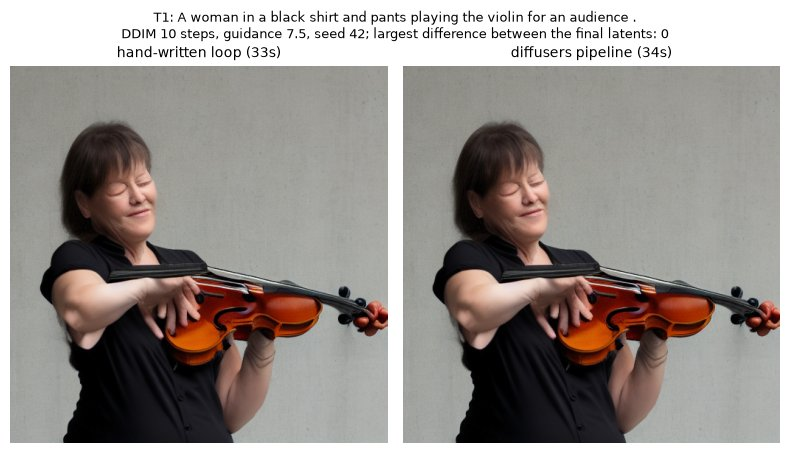

In [4]:
SCHEDULERS = {'ddim': DDIMScheduler, 'dpmpp_2m': DPMSolverMultistepScheduler, 'euler_a': EulerAncestralDiscreteScheduler}

def make_scheduler(name, **options):
    return SCHEDULERS[name].from_config(TRAINING_SCHEDULE, **options)

def sample_by_hand(vectors, steps, guidance, seed, scheduler):
    # Text-to-image written out: CLIP vectors -> U-Net with CFG at every step. Returns the final latent.
    generator = torch.Generator('cpu').manual_seed(seed)
    latents = torch.randn((1, 4, LATENT_SIZE, LATENT_SIZE), generator=generator, dtype=DTYPE).to(DEVICE)
    latents = latents * scheduler.init_noise_sigma
    scheduler.set_timesteps(steps, device=DEVICE)
    text = torch.cat([empty_vectors, vectors])        # batch of two: empty caption, then the real caption
    with torch.inference_mode():
        for t in scheduler.timesteps:
            model_input = scheduler.scale_model_input(torch.cat([latents, latents]), t)
            noise_empty, noise_caption = unet(model_input, t, encoder_hidden_states=text).sample.chunk(2)
            noise = noise_empty + guidance * (noise_caption - noise_empty)    # classifier-free guidance
            latents = scheduler.step(noise, t, latents).prev_sample
    return latents

def decode(latents):
    # VAE decoder, then the same safety check the pipeline applies (a flagged image comes back black).
    with torch.inference_mode():
        image = vae.decode(latents / vae.config.scaling_factor).sample
        image, flagged = pipe.run_safety_checker(image, DEVICE, DTYPE)
    keep = [True] * len(image) if flagged is None else [not f for f in flagged]
    return pipe.image_processor.postprocess(image, output_type='pil', do_denormalize=keep)[0]

CHECK_STEPS = 10   # a short run is enough: the point is exact agreement, not image quality
check_row = test_rows[0]
started = time.perf_counter()
hand_latents = sample_by_hand(caption_vectors[check_row['id']], CHECK_STEPS, BASELINE['guidance'], SEED, make_scheduler('ddim'))
hand_seconds = time.perf_counter() - started
pipe.scheduler = make_scheduler('ddim')
started = time.perf_counter()
pipeline_latents = pipe(prompt_embeds=caption_vectors[check_row['id']], negative_prompt_embeds=empty_vectors,
                        guidance_scale=BASELINE['guidance'], num_inference_steps=CHECK_STEPS,
                        generator=torch.Generator('cpu').manual_seed(SEED), output_type='latent').images
pipeline_seconds = time.perf_counter() - started
# Compare the final latents, before the VAE and the safety checker.
latent_gap = float((hand_latents - pipeline_latents).abs().max())
record_check('hand_loop_matches_pipeline', latent_gap <= (1e-5 if DTYPE == torch.float32 else 1e-2))
by_hand, by_pipeline = decode(hand_latents), decode(pipeline_latents)
print(f'Largest difference between the final latents of the hand-written loop and the pipeline: {latent_gap:g}')
by_hand.save(OUT / 'integration_by_hand.png')
by_pipeline.save(OUT / 'integration_pipeline.png')

fig, axes = plt.subplots(1, 2, figsize=(8, 4.6))
for ax, image, title in zip(axes, (by_hand, by_pipeline),
                            (f'hand-written loop ({hand_seconds:.0f}s)', f'diffusers pipeline ({pipeline_seconds:.0f}s)')):
    ax.imshow(image)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
fig.suptitle(textwrap.fill(f"{check_row['label']}: {check_row['caption']}", 90) +
             f"\nDDIM {CHECK_STEPS} steps, guidance {BASELINE['guidance']}, seed {SEED}; "
             f"largest difference between the final latents: {latent_gap:g}", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'integration_check.png', dpi=120, bbox_inches='tight')
plt.show()

## 2. Baseline conditional generation

The first eight test captions, generated with the Milestone 1 settings (DDIM, 30 steps, guidance 7.5, seeds 42–49).

Each image gets a **CLIP score**: 100 × the cosine similarity between the image and its caption. Higher means a closer match. The score comes from a separate CLIP model (LAION ViT-B/32), not from the text encoder that guided the generation. The real Flickr30k photo of each caption is scored the same way, as a reference point.

In [5]:
scorer_args = dict(revision=SCORER_REVISION)
try:
    scorer = CLIPModel.from_pretrained(SCORER_ID, local_files_only=True, use_safetensors=True, **scorer_args)
    scorer_processor = CLIPProcessor.from_pretrained(SCORER_ID, local_files_only=True, **scorer_args)
except OSError:
    scorer = CLIPModel.from_pretrained(SCORER_ID, use_safetensors=True, **scorer_args)
    scorer_processor = CLIPProcessor.from_pretrained(SCORER_ID, **scorer_args)
scorer = scorer.to(DEVICE).eval()

def clip_score(image, caption):
    inputs = scorer_processor(text=[caption], images=[image], return_tensors='pt', padding=True, truncation=True).to(DEVICE)
    with torch.inference_mode():
        image_vector = scorer.get_image_features(pixel_values=inputs['pixel_values'])
        text_vector = scorer.get_text_features(input_ids=inputs['input_ids'], attention_mask=inputs['attention_mask'])
    return max(100 * float(torch.nn.functional.cosine_similarity(image_vector, text_vector)), 0.0)

log = []
def generate(row, section, setting, seed, scheduler='ddim', steps=30, guidance=7.5, **options):
    # Generate one image with the pipeline, save and score it, and add a row to the generation log.
    pipe.scheduler = make_scheduler(scheduler, **options)
    vectors = empty_vectors if guidance == 0 else caption_vectors[row['id']]    # guidance 0: caption ignored
    started = time.perf_counter()
    result = pipe(prompt_embeds=vectors, negative_prompt_embeds=empty_vectors,
                  guidance_scale=max(guidance, 1.0),      # at 1 or below, diffusers runs the caption pass only
                  num_inference_steps=steps, generator=torch.Generator('cpu').manual_seed(seed))
    seconds = time.perf_counter() - started
    image = result.images[0]
    flagged = bool(result.nsfw_content_detected and result.nsfw_content_detected[0])
    filename = OUT / 'images' / f"{section}_{row['label']}_{setting}.png"
    image.save(filename)
    record = {'section': section, 'caption_id': row['label'], 'split': row['split'], 'setting': setting,
              'scheduler': type(pipe.scheduler).__name__, 'steps': steps, 'guidance': guidance,
              'timestep_spacing': pipe.scheduler.config.timestep_spacing,
              'karras_sigmas': bool(pipe.scheduler.config.get('use_karras_sigmas', False)),
              'beta_schedule': pipe.scheduler.config.beta_schedule, 'seed': seed, 'seconds': round(seconds, 2),
              'clip_score': float('nan') if flagged else round(clip_score(image, row['caption']), 2),  # black image: no score
              'safety_flag': flagged, 'image': filename.relative_to(NOTEBOOK_DIR).as_posix(),
              'sha256': file_sha256(filename), 'caption': row['caption']}
    log.append(record)
    pd.DataFrame(log).to_csv(OUT / 'generation_log.csv', index=False)
    print(f"[{len(log):02d}] {section:<8} {row['label']:<3} {setting:<22} {seconds:6.1f}s   CLIP score {show(record['clip_score'])}",
          flush=True)
    return image

def show(score, digits=2):
    return 'flagged' if np.isnan(score) else f'{score:.{digits}f}'

def records(frame):
    return json.loads(frame.to_json(orient='records'))    # NaN becomes null in run.json

def caption_grid(images, titles, captions, filename, ncols=4):
    # Caption above each image, wrapped narrower than the panel so neighbouring captions never touch.
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 4.0 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title, caption in zip(axes.flat, images, titles, captions):
        ax.imshow(image)
        wrapped = textwrap.fill(caption, 40).replace('\n.', ' .')    # keep Flickr30k's closing ' .' on the last line
        ax.set_title(f'{title}\n{wrapped}', fontsize=8.5)
    fig.tight_layout(pad=0.6, h_pad=1.2)
    fig.savefig(OUT / filename, dpi=120, bbox_inches='tight')
    plt.show()

def sweep_grid(images, scores, row_labels, col_labels, filename):
    # images[r][c]: caption r, setting c; the CLIP score is printed under each image.
    fig, axes = plt.subplots(len(row_labels), len(col_labels),
                             figsize=(2.1 * len(col_labels), 2.4 * len(row_labels)), squeeze=False)
    for r, row_label in enumerate(row_labels):
        for c, col_label in enumerate(col_labels):
            ax = axes[r][c]
            ax.imshow(images[r][c])
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel(show(scores[r][c], 1), fontsize=8, labelpad=2)
            if r == 0:
                ax.set_title(col_label, fontsize=8.5)
            if c == 0:
                ax.set_ylabel(row_label, fontsize=10)
    fig.tight_layout(pad=0.4)
    fig.savefig(OUT / filename, dpi=120, bbox_inches='tight')
    plt.show()

real_scores = {}
for row in test_rows:
    with Image.open(NOTEBOOK_DIR / row['image']) as photo:
        real_scores[row['id']] = round(clip_score(photo.convert('RGB'), row['caption']), 2)
print('Scorer loaded; mean CLIP score of the real test photos:', round(float(np.mean(list(real_scores.values()))), 2))

Scorer loaded; mean CLIP score of the real test photos: 31.31


[01] baseline T1  DDIM-30_g7.5            104.3s   CLIP score 33.65


[02] baseline T2  DDIM-30_g7.5            103.7s   CLIP score 33.88


[03] baseline T3  DDIM-30_g7.5            106.0s   CLIP score 34.00


[04] baseline T4  DDIM-30_g7.5            103.9s   CLIP score 39.69


[05] baseline T5  DDIM-30_g7.5            103.9s   CLIP score 36.73


[06] baseline T6  DDIM-30_g7.5            107.0s   CLIP score 32.18


[07] baseline T7  DDIM-30_g7.5            105.8s   CLIP score 33.63


[08] baseline T8  DDIM-30_g7.5            104.2s   CLIP score 39.94


,caption,seed,seconds,"CLIP score, real photo","CLIP score, generated"
0,T1,42,104.33,23.80,33.65
1,T2,43,103.68,36.74,33.88
2,T3,44,105.97,31.27,34.00
3,T4,45,103.91,34.24,39.69
4,T5,46,103.87,37.20,36.73
5,T6,47,106.98,28.80,32.18
6,T7,48,105.76,33.83,33.63
7,T8,49,104.21,24.58,39.94


Mean CLIP score: generated 35.46, real photos 31.31; mean time 104.8s per image


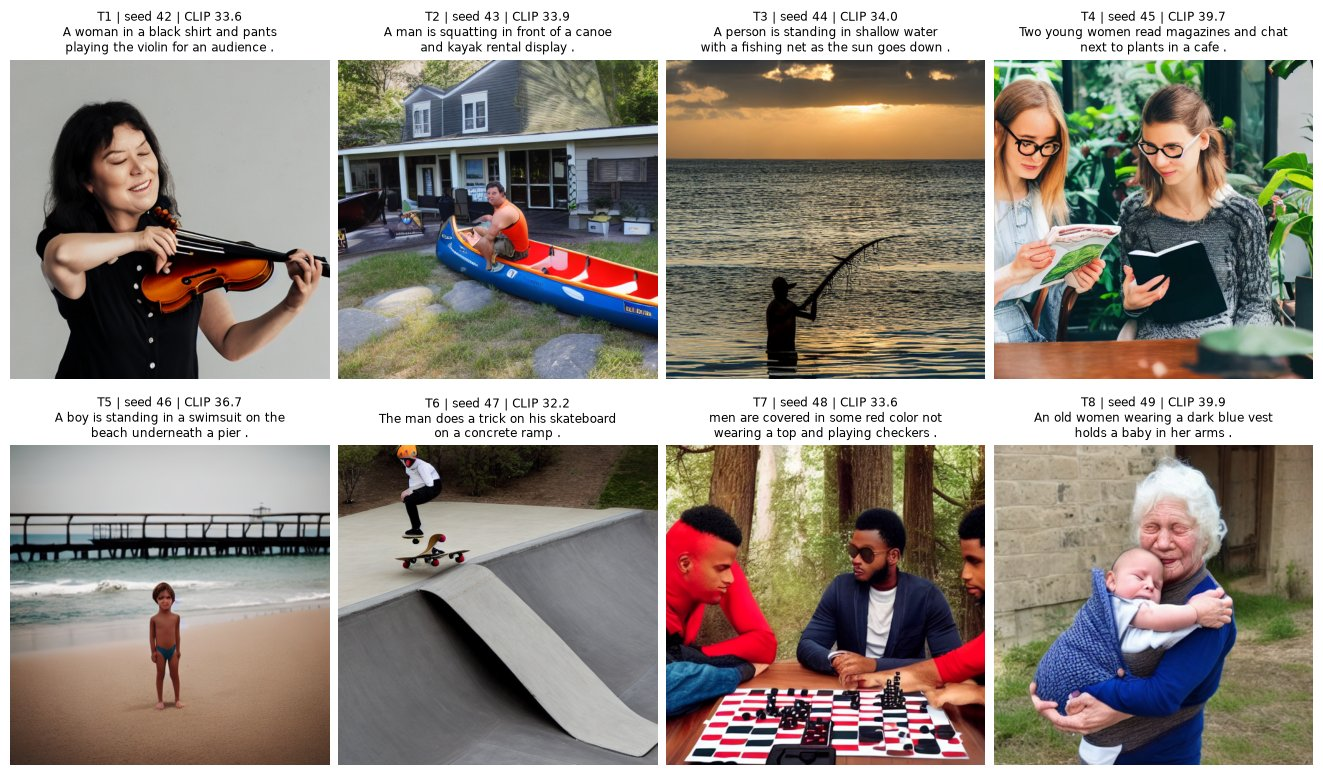

In [6]:
baseline_images = {}
for number, row in enumerate(test_rows):
    baseline_images[row['id']] = generate(row, 'baseline', 'DDIM-30_g7.5', SEED + number, **BASELINE)

baseline_log = [r for r in log if r['section'] == 'baseline']
baseline_table = pd.DataFrame([{'caption': r['caption_id'], 'seed': r['seed'], 'seconds': r['seconds'],
                                'CLIP score, real photo': real_scores[row['id']], 'CLIP score, generated': r['clip_score']}
                               for row, r in zip(test_rows, baseline_log)])
display(baseline_table)
print(f"Mean CLIP score: generated {baseline_table['CLIP score, generated'].mean():.2f}, "
      f"real photos {baseline_table['CLIP score, real photo'].mean():.2f}; "
      f"mean time {baseline_table['seconds'].mean():.1f}s per image")
caption_grid([baseline_images[row['id']] for row in test_rows],
             [f"{row['label']} | seed {r['seed']} | CLIP {show(r['clip_score'], 1)}" for row, r in zip(test_rows, baseline_log)],
             [row['caption'] for row in test_rows], 'baseline_test.png')

## 3. Tuning classifier-free guidance and the noise schedule

Settings are tuned on the first four **validation** captions (seeds 42–45), so the test captions are never used to choose them. One thing changes at a time: first the guidance scale with the Milestone 1 sampler, then the sampler at the chosen scale.

**Selection rule, fixed before the run.** A setting whose mean CLIP score is within 0.5 points of the best counts as equally good. Among those, take the smallest guidance scale, then the sampler with the fewest steps. A lower scale is known to keep colours more natural and images more varied, and fewer steps is faster.

### 3a. Classifier-free guidance

[09] cfg      V1  DDIM-30_g0               59.3s   CLIP score 15.47


[10] cfg      V1  DDIM-30_g1               57.9s   CLIP score 21.64


[11] cfg      V1  DDIM-30_g3              115.6s   CLIP score 23.03


[12] cfg      V1  DDIM-30_g5              118.2s   CLIP score 21.30


[13] cfg      V1  DDIM-30_g7.5            117.9s   CLIP score 23.12


[14] cfg      V1  DDIM-30_g10             116.4s   CLIP score 23.98


... (20 outputs left out)

[35] cfg      V4  DDIM-30_g10             115.9s   CLIP score 38.68


[36] cfg      V4  DDIM-30_g15             116.5s   CLIP score 43.40


,g = 0,g = 1,g = 3,g = 5,g = 7.5,g = 10,g = 15
caption_id,,,,,,,
V1,15.47,21.64,23.03,21.30,23.12,23.98,22.84
V2,3.45,22.82,27.26,29.78,32.54,34.01,33.78
V3,11.26,29.79,34.39,41.48,40.49,40.06,39.82
V4,6.90,11.42,37.47,38.22,39.17,38.68,43.40
mean CLIP score,9.27,21.42,30.54,32.70,33.83,34.18,34.96
mean seconds,51.48,51.16,95.30,95.44,99.05,102.42,95.91
flagged images,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Chosen guidance scale: 15


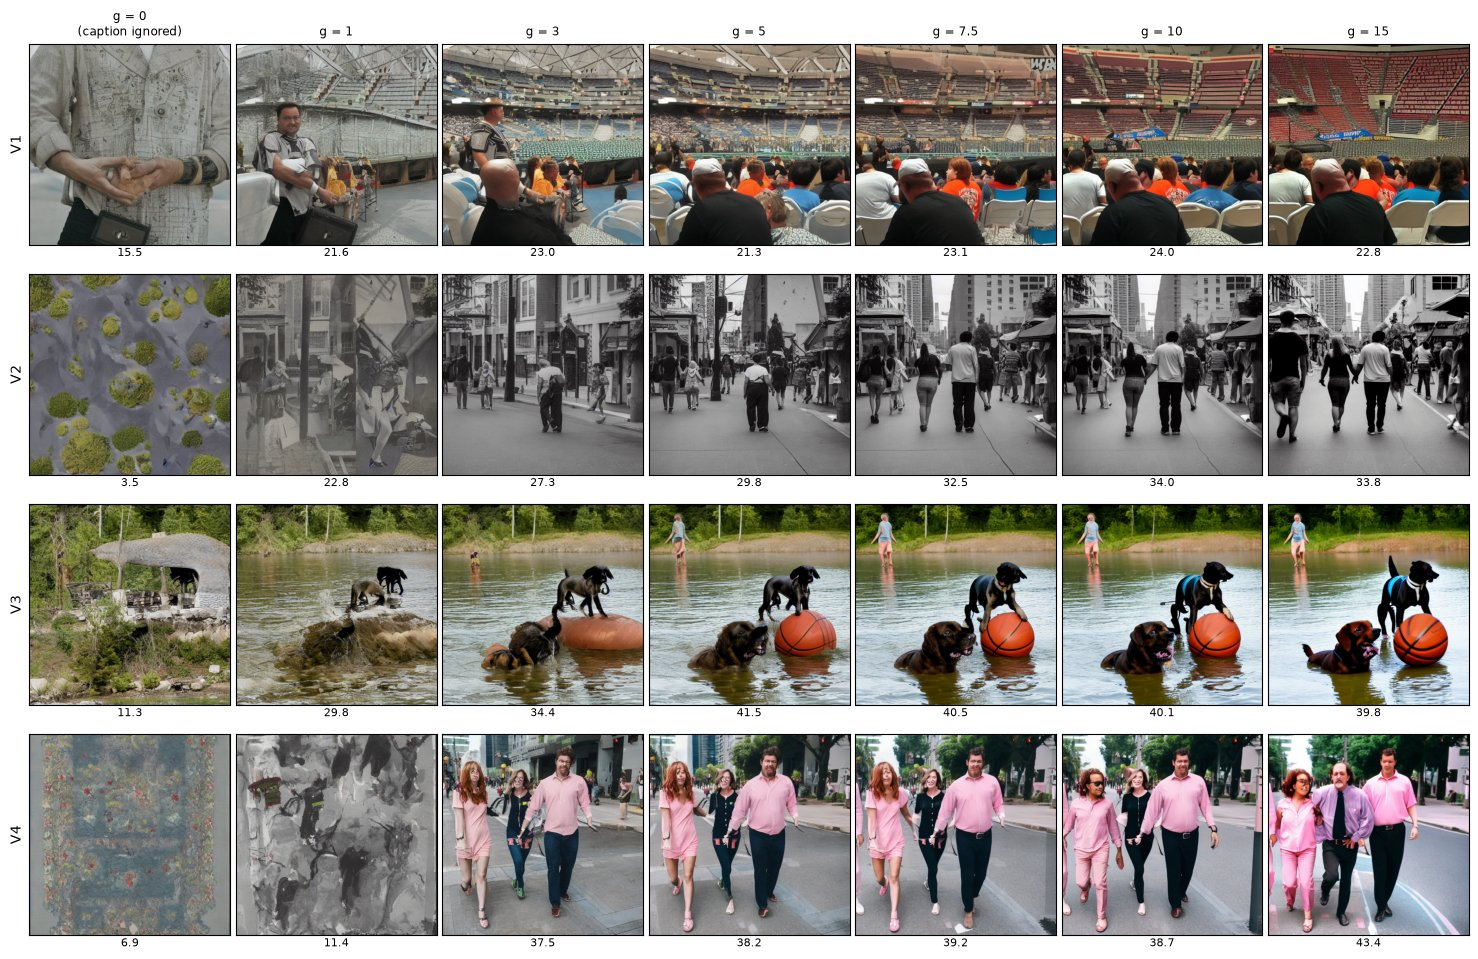

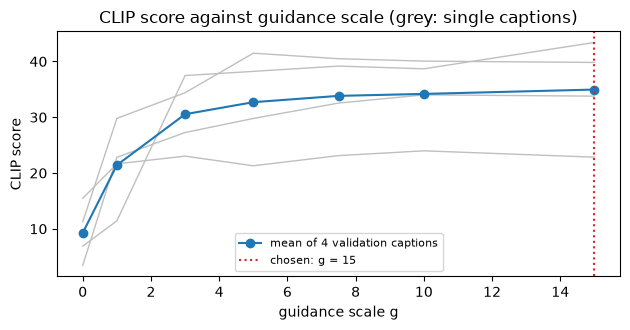

In [7]:
GUIDANCE_SCALES = [0, 1, 3, 5, 7.5, 10, 15]
cfg_images = {}
for number, row in enumerate(val_rows):
    for g in GUIDANCE_SCALES:
        cfg_images[row['id'], g] = generate(row, 'cfg', f'DDIM-30_g{g}', SEED + number, scheduler='ddim', steps=30, guidance=g)

cfg_log = pd.DataFrame([r for r in log if r['section'] == 'cfg'])
cfg_summary = cfg_log.groupby('guidance').agg(mean_clip_score=('clip_score', 'mean'), mean_seconds=('seconds', 'mean'),
                                              flagged=('safety_flag', 'sum')).round(2)
guided = cfg_summary[cfg_summary.index > 1]
CHOSEN_GUIDANCE = float(guided.index[guided['mean_clip_score'] >= guided['mean_clip_score'].max() - TOLERANCE].min())

cfg_view = cfg_log.pivot(index='caption_id', columns='guidance', values='clip_score')
cfg_view.loc['mean CLIP score'] = cfg_summary['mean_clip_score']
cfg_view.loc['mean seconds'] = cfg_summary['mean_seconds']
cfg_view.loc['flagged images'] = cfg_summary['flagged']
cfg_view.columns = [f'g = {g:g}' for g in cfg_view.columns]
display(cfg_view)
print(f'Chosen guidance scale: {CHOSEN_GUIDANCE:g}')

sweep_grid([[cfg_images[row['id'], g] for g in GUIDANCE_SCALES] for row in val_rows],
           [[cfg_log.set_index(['caption_id', 'guidance']).loc[(row['label'], g), 'clip_score'] for g in GUIDANCE_SCALES]
            for row in val_rows],
           [row['label'] for row in val_rows],
           ['g = 0\n(caption ignored)' if g == 0 else f'g = {g:g}' for g in GUIDANCE_SCALES], 'cfg_grid.png')

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for row in val_rows:
    scores = cfg_log[cfg_log['caption_id'] == row['label']]
    ax.plot(scores['guidance'], scores['clip_score'], color='0.75', linewidth=1)
ax.plot(cfg_summary.index, cfg_summary['mean_clip_score'], 'o-', color='C0', label=f'mean of {N_VAL} validation captions')
ax.axvline(CHOSEN_GUIDANCE, color='C3', linestyle=':', label=f'chosen: g = {CHOSEN_GUIDANCE:g}')
ax.set(xlabel='guidance scale g', ylabel='CLIP score', title='CLIP score against guidance scale (grey: single captions)')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'cfg_curve.png', dpi=120)
plt.show()

### 3b. Noise schedule

SD 1.5 was trained on 1,000 noise levels set by a *scaled-linear* beta schedule. At sampling time we choose which of those levels to visit and how to move between them:

- **steps:** 30 (Milestone 1) or 15;
- **timestep spacing:** `leading` (Milestone 1) never visits the noisiest level, while `trailing` starts at t = 999 (see the table below);
- **Karras sigmas:** spend more of the steps at low noise, where fine detail forms;
- **solver:** DDIM (deterministic), DPM-Solver++ 2M (a second-order solver designed for few steps) and Euler ancestral (adds fresh noise at every step);
- **control:** DDIM with a *linear* beta schedule, which no longer matches training.

Guidance stays at the scale chosen in 3a. The Milestone 1 sampler at that scale was already generated in the CFG sweep, so it is reused, not generated twice.

,setting,solver,steps,first timestep,last timestep,timestep spacing,Karras sigmas,beta schedule
0,DDIM-30,DDIMScheduler,30,958,1,leading,False,scaled_linear
1,DDIM-30-trailing,DDIMScheduler,30,999,32,trailing,False,scaled_linear
2,DDIM-15,DDIMScheduler,15,925,1,leading,False,scaled_linear
3,DPMpp-15,DPMSolverMultistepScheduler,15,999,67,linspace,False,scaled_linear
4,DPMpp-15-Karras,DPMSolverMultistepScheduler,15,999,0,linspace,True,scaled_linear
5,EulerA-30,EulerAncestralDiscreteScheduler,30,999,0,linspace,False,scaled_linear
6,DDIM-30-linear-betas,DDIMScheduler,30,958,1,leading,False,linear


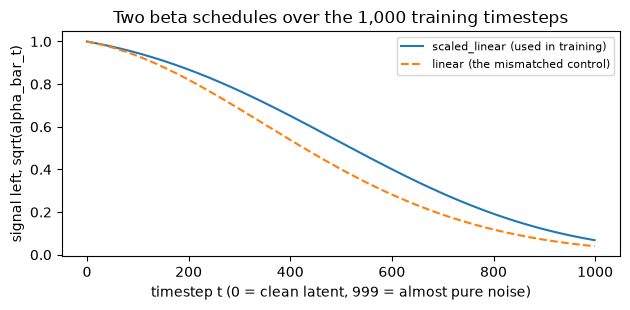

In [8]:
SCHEDULES = [   # (setting, solver, steps, scheduler options)
    ('DDIM-30', 'ddim', 30, {}),                                        # Milestone 1 sampler, 'leading' spacing
    ('DDIM-30-trailing', 'ddim', 30, {'timestep_spacing': 'trailing'}),
    ('DDIM-15', 'ddim', 15, {}),
    ('DPMpp-15', 'dpmpp_2m', 15, {}),
    ('DPMpp-15-Karras', 'dpmpp_2m', 15, {'use_karras_sigmas': True}),
    ('EulerA-30', 'euler_a', 30, {}),
    ('DDIM-30-linear-betas', 'ddim', 30, {'beta_schedule': 'linear'}),  # deliberate mismatch with training
]
CONTROL = 'DDIM-30-linear-betas'

schedule_info = []
for setting, name, steps, options in SCHEDULES:
    scheduler = make_scheduler(name, **options)
    scheduler.set_timesteps(steps)
    schedule_info.append({'setting': setting, 'solver': type(scheduler).__name__, 'steps': steps,
                          'first timestep': int(scheduler.timesteps[0]), 'last timestep': int(scheduler.timesteps[-1]),
                          'timestep spacing': scheduler.config.timestep_spacing,
                          'Karras sigmas': bool(scheduler.config.get('use_karras_sigmas', False)),
                          'beta schedule': scheduler.config.beta_schedule})
display(pd.DataFrame(schedule_info))

fig, ax = plt.subplots(figsize=(6.4, 3.2))
for beta_schedule, style, label in (('scaled_linear', '-', 'scaled_linear (used in training)'),
                                    ('linear', '--', 'linear (the mismatched control)')):
    signal = np.sqrt(make_scheduler('ddim', beta_schedule=beta_schedule).alphas_cumprod.numpy())
    ax.plot(np.arange(len(signal)), signal, style, label=label)
ax.set(xlabel='timestep t (0 = clean latent, 999 = almost pure noise)', ylabel='signal left, sqrt(alpha_bar_t)',
       title='Two beta schedules over the 1,000 training timesteps')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'beta_schedules.png', dpi=120)
plt.show()

[37] schedule V1  DDIM-30-trailing        117.3s   CLIP score 24.88


[38] schedule V1  DDIM-15                  60.7s   CLIP score 22.32


[39] schedule V1  DPMpp-15                 61.2s   CLIP score 20.76


[40] schedule V1  DPMpp-15-Karras          61.0s   CLIP score 23.80


[41] schedule V1  EulerA-30               116.7s   CLIP score 26.05


[42] schedule V1  DDIM-30-linear-betas    117.6s   CLIP score 22.25


... (16 outputs left out)

[59] schedule V4  EulerA-30               115.4s   CLIP score 41.46


[60] schedule V4  DDIM-30-linear-betas    111.7s   CLIP score 38.93


setting,DDIM-30,DDIM-30-trailing,DDIM-15,DPMpp-15,DPMpp-15-Karras,EulerA-30,DDIM-30-linear-betas
caption_id,,,,,,,
V1,22.84,24.88,22.32,20.76,23.80,26.05,22.25
V2,33.78,31.44,35.67,35.94,33.04,34.24,31.30
V3,39.82,39.06,42.51,39.68,38.45,37.29,39.09
V4,43.40,37.58,38.55,36.12,39.27,41.46,38.93
mean CLIP score,34.96,33.24,34.76,33.12,33.64,34.76,32.89
mean seconds,95.91,117.26,61.36,63.14,61.41,116.72,115.59
flagged images,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Chosen sampler at g = 15: DDIM-15


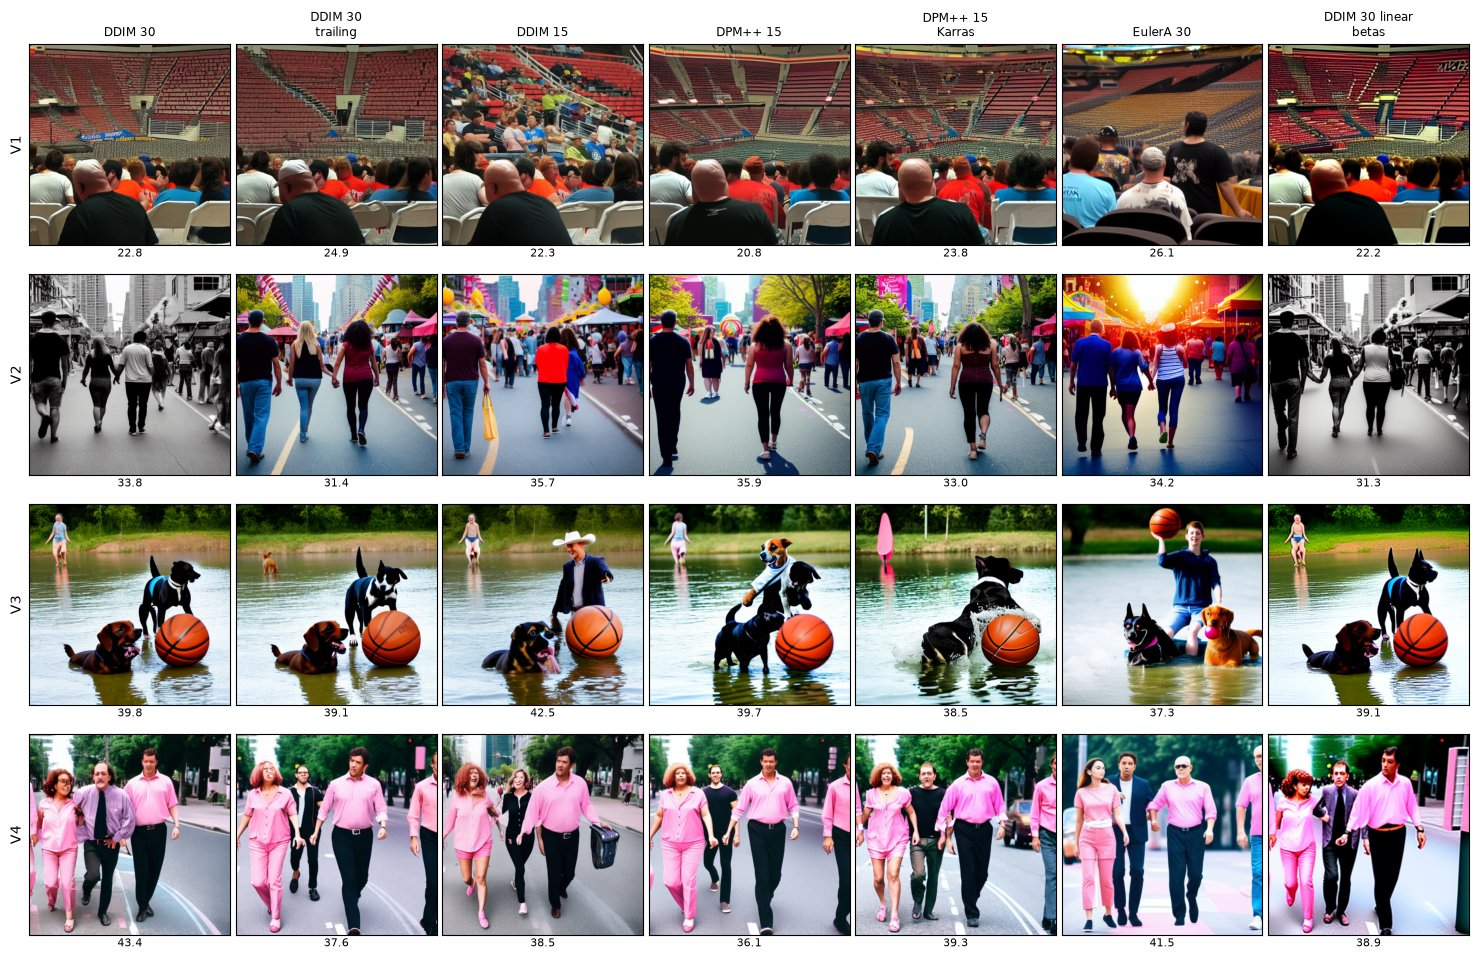

In [9]:
schedule_images = {}
for number, row in enumerate(val_rows):
    for setting, name, steps, options in SCHEDULES:
        if setting == 'DDIM-30':     # same settings as the CFG-sweep image at the chosen scale
            schedule_images[row['id'], setting] = cfg_images[row['id'], CHOSEN_GUIDANCE]
            continue
        schedule_images[row['id'], setting] = generate(row, 'schedule', setting, SEED + number, scheduler=name,
                                                       steps=steps, guidance=CHOSEN_GUIDANCE, **options)

order = [s[0] for s in SCHEDULES]
reused = [dict(r, setting='DDIM-30') for r in log if r['section'] == 'cfg' and r['guidance'] == CHOSEN_GUIDANCE]
schedule_log = pd.DataFrame(reused + [r for r in log if r['section'] == 'schedule'])
schedule_summary = (schedule_log.groupby('setting').agg(steps=('steps', 'first'), mean_clip_score=('clip_score', 'mean'),
                                                        mean_seconds=('seconds', 'mean'), flagged=('safety_flag', 'sum'))
                    .reindex(order).round(2))
candidates = schedule_summary.drop(index=CONTROL)
candidates = candidates[candidates['mean_clip_score'] >= candidates['mean_clip_score'].max() - TOLERANCE]
CHOSEN_SCHEDULE = candidates.sort_values(['steps', 'mean_clip_score'], ascending=[True, False]).index[0]

schedule_view = schedule_log.pivot(index='caption_id', columns='setting', values='clip_score')[order]
schedule_view.loc['mean CLIP score'] = schedule_summary['mean_clip_score']
schedule_view.loc['mean seconds'] = schedule_summary['mean_seconds']
schedule_view.loc['flagged images'] = schedule_summary['flagged']
display(schedule_view)
print(f'Chosen sampler at g = {CHOSEN_GUIDANCE:g}: {CHOSEN_SCHEDULE}')

scores = schedule_log.set_index(['caption_id', 'setting'])['clip_score']
sweep_grid([[schedule_images[row['id'], setting] for setting in order] for row in val_rows],
           [[scores[row['label'], setting] for setting in order] for row in val_rows],
           [row['label'] for row in val_rows],
           [textwrap.fill(s.replace('DPMpp', 'DPM++').replace('-', ' '), 14) for s in order], 'schedule_grid.png')

## 4. First set of generated images

The eight test captions from section 2, with the same seeds, regenerated with the settings chosen in section 3. Every image is shown; none are hand-picked.

Chosen settings: DDIM-15_g15


[61] tuned    T1  DDIM-15_g15              56.0s   CLIP score 32.22


[62] tuned    T2  DDIM-15_g15              55.4s   CLIP score 35.37


[63] tuned    T3  DDIM-15_g15              55.4s   CLIP score 32.22


[64] tuned    T4  DDIM-15_g15              56.2s   CLIP score 44.33


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[65] tuned    T5  DDIM-15_g15              55.4s   CLIP score flagged


[66] tuned    T6  DDIM-15_g15              54.9s   CLIP score 31.51


[67] tuned    T7  DDIM-15_g15              55.1s   CLIP score 39.40


[68] tuned    T8  DDIM-15_g15              56.8s   CLIP score 39.13


,caption,"CLIP score, real photo","CLIP score, baseline","CLIP score, tuned","seconds, baseline","seconds, tuned"
0,T1,23.80,33.65,32.22,104.33,55.99
1,T2,36.74,33.88,35.37,103.68,55.35
2,T3,31.27,34.00,32.22,105.97,55.36
3,T4,34.24,39.69,44.33,103.91,56.16
4,T5,37.20,36.73,NaN,103.87,55.36
5,T6,28.80,32.18,31.51,106.98,54.88
6,T7,33.83,33.63,39.40,105.76,55.10
7,T8,24.58,39.94,39.13,104.21,56.84
8,mean,31.31,35.46,36.31,104.84,55.63


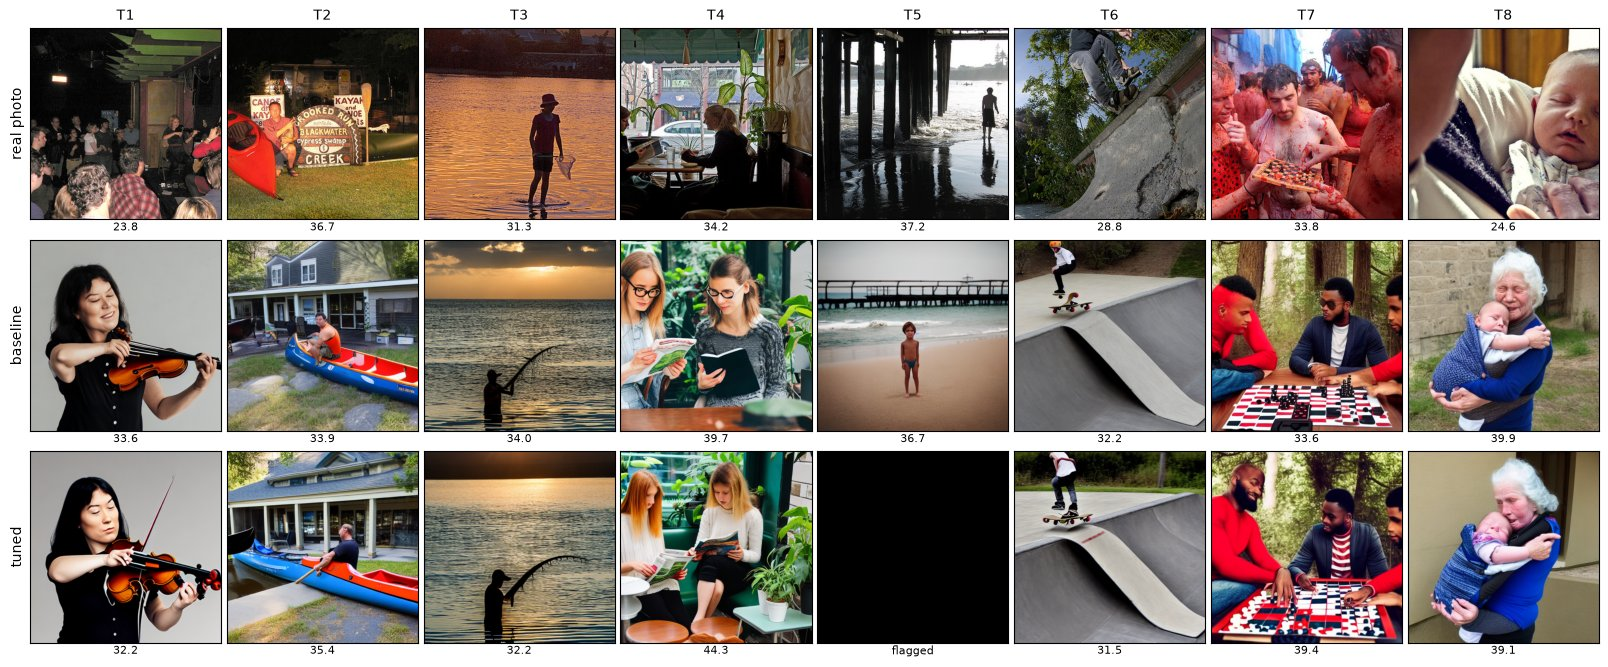

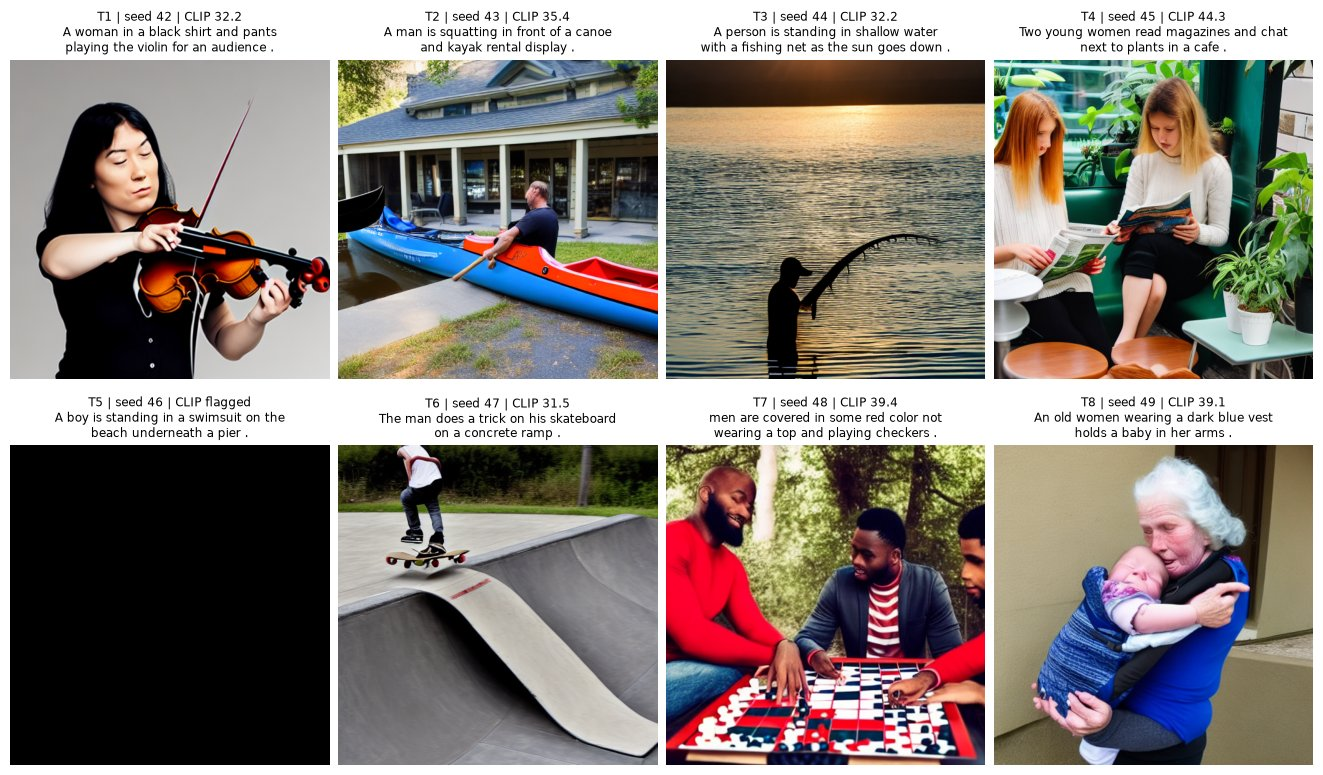

In [10]:
setting, name, steps, options = next(s for s in SCHEDULES if s[0] == CHOSEN_SCHEDULE)
TUNED = {'scheduler': name, 'steps': steps, 'guidance': CHOSEN_GUIDANCE, **options}
tuned_setting = f'{CHOSEN_SCHEDULE}_g{CHOSEN_GUIDANCE:g}'
print('Chosen settings:', tuned_setting)
if TUNED == BASELINE:
    print('These are the Milestone 1 settings, so the baseline images are the first set.')
    tuned_images, tuned_log = baseline_images, baseline_log
else:
    tuned_images = {}
    for number, row in enumerate(test_rows):
        tuned_images[row['id']] = generate(row, 'tuned', tuned_setting, SEED + number, **TUNED)
    tuned_log = [r for r in log if r['section'] == 'tuned']

comparison = pd.DataFrame([{'caption': row['label'], 'CLIP score, real photo': real_scores[row['id']],
                            'CLIP score, baseline': b['clip_score'], 'CLIP score, tuned': t['clip_score'],
                            'seconds, baseline': b['seconds'], 'seconds, tuned': t['seconds']}
                           for row, b, t in zip(test_rows, baseline_log, tuned_log)])
comparison.loc[len(comparison)] = ['mean', *comparison.drop(columns='caption').mean().round(2)]
display(comparison)

fig, axes = plt.subplots(3, N_TEST, figsize=(2.0 * N_TEST, 6.6), squeeze=False)
for c, (row, b, t) in enumerate(zip(test_rows, baseline_log, tuned_log)):
    with Image.open(NOTEBOOK_DIR / row['image']) as photo:
        panels = [(photo.convert('RGB'), real_scores[row['id']]), (baseline_images[row['id']], b['clip_score']),
                  (tuned_images[row['id']], t['clip_score'])]
    for r, (image, score) in enumerate(panels):
        ax = axes[r][c]
        ax.imshow(image)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(show(score, 1), fontsize=8, labelpad=2)
        if r == 0:
            ax.set_title(row['label'], fontsize=10)
        if c == 0:
            ax.set_ylabel(['real photo', 'baseline', 'tuned'][r], fontsize=10)
fig.tight_layout(pad=0.4)
fig.savefig(OUT / 'test_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

caption_grid([tuned_images[row['id']] for row in test_rows],
             [f"{row['label']} | seed {t['seed']} | CLIP {show(t['clip_score'], 1)}" for row, t in zip(test_rows, tuned_log)],
             [row['caption'] for row in test_rows], 'early_samples.png')

In [11]:
images_ok = True
for record in log:
    with Image.open(NOTEBOOK_DIR / record['image']) as image:
        images_ok = images_ok and image.size == (512, 512) and image.mode == 'RGB'
expected = N_TEST + N_VAL * (len(GUIDANCE_SCALES) + len(SCHEDULES) - 1) + (0 if TUNED == BASELINE else N_TEST)
record_check('every_generation_logged', len(log) == expected)
record_check('all_images_rgb_512', images_ok)

summary = {
    'started_utc': STARTED_UTC, 'completed_utc': datetime.now(timezone.utc).isoformat(),
    'environment': environment, 'model_id': MODEL_ID, 'revision': MODEL_REVISION,
    'scorer': {'model_id': SCORER_ID, 'revision': SCORER_REVISION, 'metric': '100 x cosine(image, caption)'},
    'captions': {'val': [row['id'] for row in val_rows], 'test': [row['id'] for row in test_rows]},
    'baseline_settings': BASELINE, 'tolerance': TOLERANCE,
    'integration': {'check_steps': CHECK_STEPS, 'max_latent_difference': latent_gap,
                    'max_embedding_difference': embedding_gap},
    'guidance_sweep': records(cfg_summary.reset_index()),
    'schedule_sweep': records(schedule_summary.reset_index()),
    'chosen': {'guidance': CHOSEN_GUIDANCE, 'sampler': CHOSEN_SCHEDULE, 'settings': TUNED},
    'test_comparison': records(comparison),
    'images_generated': len(log), 'generation_seconds': round(sum(r['seconds'] for r in log), 1),
    'safety_flags': sum(r['safety_flag'] for r in log),
    'checks': checks,
}
write_json(OUT / 'run.json', summary)
display(pd.DataFrame([{'check': name, 'result': 'PASS' if passed else 'FAIL'} for name, passed in checks.items()]))
display(Markdown(f"**Completed:** {len(log)} images in {summary['generation_seconds'] / 60:.0f} minutes of generation; "
                 f"chosen settings {tuned_setting}; {len(checks)}/{len(checks)} checks passed. "
                 f"Log: `artifacts/milestone2/generation_log.csv`; summary: `artifacts/milestone2/run.json`."))

,check,result
0,captions_loaded,PASS
1,text_vectors_fit_unet_cross_attention,PASS
2,latent_is_4x64x64,PASS
3,milestone1_embeddings_found,PASS
4,saved_embeddings_match_fresh_encoding,PASS
5,hand_loop_matches_pipeline,PASS
6,every_generation_logged,PASS
7,all_images_rgb_512,PASS


**Completed:** 68 images in 96 minutes of generation; chosen settings DDIM-15_g15; 8/8 checks passed. Log: `artifacts/milestone2/generation_log.csv`; summary: `artifacts/milestone2/run.json`.

## Observations

Measured in the run above: 68 images, one seed per caption. Differences of about 1 CLIP point between settings are within the noise of 4 captions.

1. **The integration is exact.** The hand-written loop and the diffusers pipeline end on the same latent (largest difference 0). Milestone 1's saved caption embeddings equal a fresh encoding.
2. **Guidance is what makes the caption matter.** The mean CLIP score is 9.3 when the caption is ignored (g = 0) and 21.4 with the caption but no guidance (g = 1). Scenes become coherent from g = 3 (30.5). Guidance doubles the cost of each step, because the U-Net runs twice: about 51 s against 95–102 s per 30-step image.
3. **CLIP score alone over-rewards guidance.** The score kept rising up to g = 15 (34.2 at g = 10, 35.0 at g = 15), so the fixed rule chose g = 15. That last gain came from one caption (V4: 38.7 → 43.4) while the other three dropped slightly, and the images become oversaturated: V4's "pink shirt" spreads to most of the people. The scale should be re-checked with a realism metric against real photos (KID or FID). In the grids, g = 7.5–10 already gives coherent, more natural images.
4. **Fifteen steps are enough.** At g = 15, DDIM with 15 steps scored 34.8 against 35.0 for 30 steps, at about 60 s instead of 96–117 s per image. Trailing spacing (33.2) and DPM-Solver++ with 15 steps (33.1, or 33.6 with Karras sigmas) did not beat it on these captions. The sampler can change more than detail: with the same seed, V2 comes out black-and-white with the Milestone 1 sampler and in colour with the others.
5. **The mismatched beta schedule did less damage than expected.** With linear betas, DDIM kept the same compositions as with the trained schedule, but the mean CLIP score fell by 2.1 points (32.9).
6. **First set on the test captions.** On the 7 test captions with both images, DDIM 15 with g = 15 scores 36.3 against 35.3 for the Milestone 1 settings (3 captions better, 4 worse), at 56 s instead of 105 s per image. The safety checker blacked out one of the 68 images (T5, a boy in a swimsuit).
7. **What the model gets wrong.** The main subject is always right, but details go missing: no audience (T1), a fishing rod instead of a net (T3), a skateboard floating away from its rider (T6), and "not wearing a top" ignored (T7), since CLIP-style text encoders handle negation poorly. The generated images look like bright, centred stock photos, while Flickr30k photos are candid and often dim. That is why the generated images out-score the real photos (35.5 against 31.3): CLIP score measures caption match, not realism. Closing this gap is the aim of the LoRA fine-tuning on the 2,400 training pairs.